In [ ]:
# Correlation Relationship
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
df = pd.read_csv(r'SEM 6\DS Lab\reddit_dead_internet_analysis_2026.csv')

In [77]:
# Convert boolean columns
df['contains_links'] = df['contains_links'].astype(bool)
df['is_bot_flag'] = df['is_bot_flag'].astype(bool)

# Drop non-numeric columns for distribution work
numeric_cols = df.select_dtypes(include=np.number).columns
df_num = df[numeric_cols].copy()

# Remove duplicates
df_num = df_num.drop_duplicates()

# Remove missing
df_num = df_num.dropna()

In [78]:
from scipy.stats import median_abs_deviation

def remove_outliers_mad(df, threshold=3.5):
    df_clean = df.copy()
    for col in df.columns:
        median = np.median(df[col])
        mad = median_abs_deviation(df[col])
        modified_z = 0.6745 * (df[col] - median) / mad
        df_clean = df_clean[np.abs(modified_z) < threshold]
    return df_clean

df_clean = remove_outliers_mad(df_num)


C:\Users\siddi\AppData\Local\Temp\ipykernel_9944\3408063087.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_clean = df_clean[np.abs(modified_z) < threshold]
C:\Users\siddi\AppData\Local\Temp\ipykernel_9944\3408063087.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_clean = df_clean[np.abs(modified_z) < threshold]
C:\Users\siddi\AppData\Local\Temp\ipykernel_9944\3408063087.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_clean = df_clean[np.abs(modified_z) < threshold]


In [79]:
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method='yeo-johnson')

df_transformed = pd.DataFrame(
    pt.fit_transform(df_clean),
    columns=df_clean.columns
)

In [80]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_final = pd.DataFrame(
    scaler.fit_transform(df_transformed),
    columns=df_transformed.columns
)

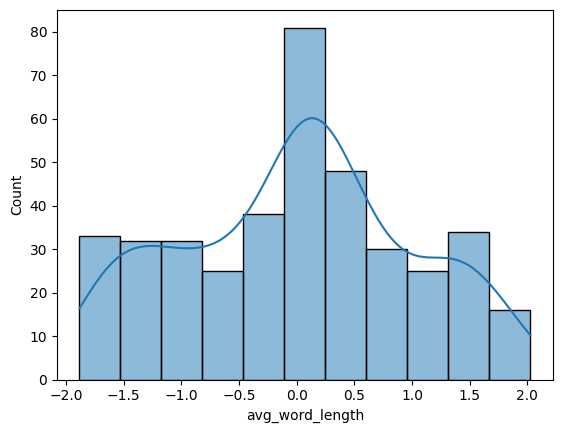

In [112]:
sns.histplot(df_final['avg_word_length'], kde=True)
plt.show()

In [82]:
from scipy.stats import shapiro

stat, p = shapiro(df_final['reply_delay_seconds'])
print("p-value:", p)

p-value: 1.6685024310874157e-21


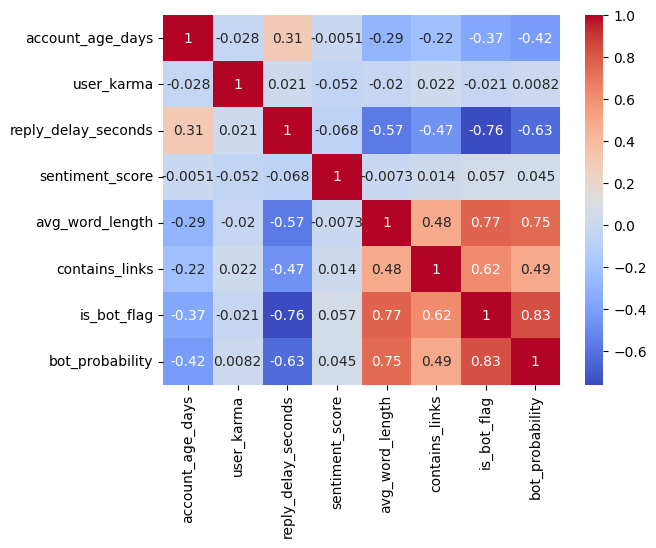

In [83]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

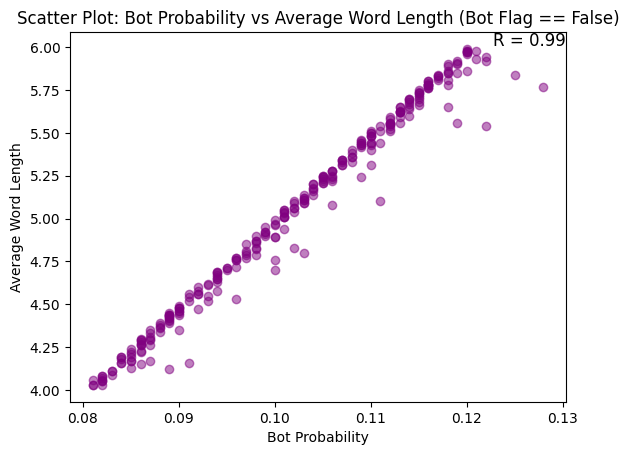

In [120]:
# Scatter plot for avg_word_length vs bot_probability for bot_flag == True from df
plt.scatter(df[df['is_bot_flag']==False]['bot_probability'], df[df['is_bot_flag']==False]['avg_word_length'], c='purple', alpha=0.5)
plt.xlabel('Bot Probability')
plt.ylabel('Average Word Length')
plt.title('Scatter Plot: Bot Probability vs Average Word Length (Bot Flag == False)')
# Display R at the top right corner of the plot
r_value = df[df['is_bot_flag']==False]['bot_probability'].corr(df[df['is_bot_flag']==False]['avg_word_length'])
plt.text(1, 1, f'R = {r_value:.2f}', transform=plt.gca().transAxes, fontsize=12, ha='right', va='top')
plt.show()

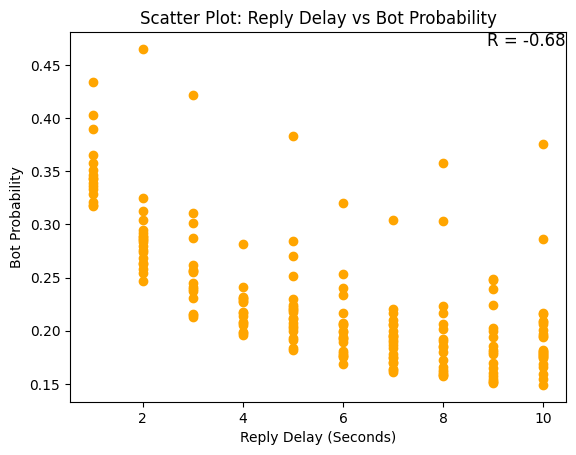

In [ ]:
# Scatter plot for reply_delay_seconds vs bot_probability colored by is_bot_flag == True from df
plt.scatter(df[df['is_bot_flag']==True]['reply_delay_seconds'], df[df['is_bot_flag']==True]['bot_probability'], c='orange', label='Is Bot Flag = True')
# plt.scatter(df[df['is_bot_flag']==False]['reply_delay_seconds'], df[df['is_bot_flag']==False]['bot_probability'], c='blue', label='Is Bot Flag = False')
plt.xlabel('Reply Delay (Seconds)')
plt.ylabel('Bot Probability')
plt.title('Scatter Plot: Reply Delay vs Bot Probability')
# Display R at the top right corner of the plot
r_value = df[df['is_bot_flag']==True]['reply_delay_seconds'].corr(df[df['is_bot_flag']==True]['bot_probability'])
plt.text(1, 1, f'R = {r_value:.2f}', transform=plt.gca().transAxes, fontsize=12, ha='right', va='top')
plt.show()

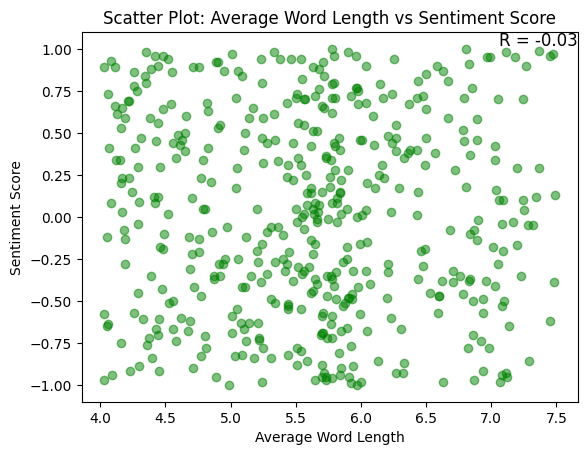

In [118]:
# Scatter plot for avg_word_length vs sentiment_score 
plt.scatter(df['avg_word_length'], df['sentiment_score'], c='green', alpha=0.5)
plt.xlabel('Average Word Length')
plt.ylabel('Sentiment Score')
plt.title('Scatter Plot: Average Word Length vs Sentiment Score')
# Display R at the top right corner of the plot
r_value = df['avg_word_length'].corr(df['sentiment_score'])
plt.text(1, 1, f'R = {r_value:.2f}', transform=plt.gca().transAxes, fontsize=12, ha='right', va='top')
plt.show() 